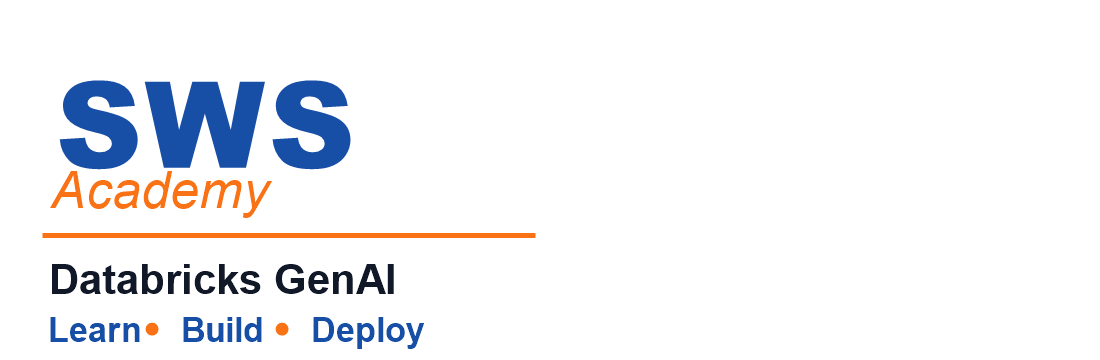

# Demo - Model Development with Genie Code

In this demo, we use **Genie Code** operating in **Agent Mode** to drive a complete, end-to-end machine learning workflow on Databricks — from loading a Feature Store dataset through registering a production-ready classifier in Unity Catalog. Rather than writing code directly, we express intent through structured natural language prompts and observe how Genie Code generates, executes, and tracks each step in context.

The workflow follows four explicit phases: **Explore** (data loading and EDA), **Iterate** (synthesizing findings into a modeling plan), **Build** (feature engineering pipeline and MLflow-tracked training), and **Validate** (model evaluation, interpretation, and Unity Catalog registration). Reference implementations are provided below each prompt so you can compare Genie Code's output against a known-good solution.



The workflow follows four explicit phases:

| Phase | What Happens |
|-------|-------------|
| **1 — Explore** | Load data, run EDA, understand the dataset |
| **2 — Iterate** | Ask Genie Code to synthesize findings and recommend next steps |
| **3 — Build** | Generate the feature engineering and training pipeline |
| **4 — Validate** | Evaluate results, interpret model behavior, register to Unity Catalog |


**Learning Objectives:**

*By the end of this demo, you will be able to:*

- Use structured natural language prompts in Genie Code Agent Mode to drive each phase of an ML workflow.
- Observe how Genie Code carries **contextual state** across prompts - from data loading through model evaluation - without re-specifying the dataset each time.
- Apply the **Explore → Iterate → Build → Validate** framework to any ML classification task on Databricks.
- Track and evaluate a Genie Code–generated classifier using **MLflow**, and register it to **Unity Catalog** with a production alias.

## REQUIRED - SELECT A COMPUTE ENVIRONMENT

<div style="border-left: 4px solid #F44336; background: #FFEBEE; padding: 16px 20px; border-radius: 4px; margin: 16px 0;">
  <div style="display: flex; align-items: flex-start; gap: 12px;">
    <div>
      <strong style="color: #C62828; font-size: 1.1em;">Select Compute</strong>
      <p style="margin: 8px 0 0 0; color: #333;">Before starting this notebook, select the required compute environment listed below.</p>
      <ul style="margin: 12px 0 0 16px; color: #333;">
        <li><strong>Serverless Compute, Version 5</strong> — <a href="https://docs.databricks.com/aws/en/compute/serverless/dependencies#-select-an-environment-version" style="color: #1976D2; text-decoration: underline;">How to select an environment version</a></li>
      </ul>
      <p style="margin: 8px 0 0 0; color: #333;"><strong>NOTE:</strong> This notebook was <strong>developed and tested using Serverless V5</strong>. Other compute options may work but are not guaranteed to support all features demonstrated, particularly the Genie Code Agent Mode integration.</p>
    </div>
  </div>
</div>

<div style="width: 100%; font-family: sans-serif;"><div style="background: #F9F7F4; border-radius: 10px; padding: 24px 28px; box-shadow: 0 2px 8px rgba(27,49,57,0.06); border-top: 6px solid #FF5F46;">  <img src="../Includes/images/genie-code.png" style="height: 64px; margin-bottom: 10px;">  <div style="font-size: 15pt; color: #0B2026; line-height: 1.7; margin-bottom: 16px;">    Want to know more about Genie Code Agent Mode and end-to-end ML workflows on Databricks? Ask Genie Code. Click on the genie icon <img src="../Includes/images/genie-icon.png" style="height: 32px; vertical-align: middle;"> and begin querying. For example, click the <strong>Copy</strong> button below and paste into <strong>Genie Code</strong>.  </div>  <div style="display: flex; align-items: center; gap: 10px; background: #fff; border: 1px solid #ddd; border-radius: 6px; padding: 10px 14px; font-size: 14pt; font-family: monospace; color: #0B2026;">    <span id="genie-query-demo" style="flex: 1;">What is Genie Code Agent Mode in Databricks? How can I use it to build an end-to-end machine learning workflow - from loading Feature Store data to logging a model in MLflow and registering it to Unity Catalog?</span>    <button onclick="      var text = document.getElementById('genie-query-demo').innerText;      var ta = document.createElement('textarea');      ta.value = text;      ta.style.position = 'fixed';      ta.style.opacity = '0';      document.body.appendChild(ta);      ta.select();      document.execCommand('copy');      document.body.removeChild(ta);      this.innerText = 'Copied!';      var btn = this;      setTimeout(function(){ btn.innerText = 'Copy'; }, 2000);    " style="background: #FF5F46; color: white; border: none; border-radius: 4px; padding: 4px 12px; font-size: 13pt; cursor: pointer; white-space: nowrap;">Copy</button>  </div></div></div>

## From Writing Code to Expressing Intent

In Modules 1 and 2, every step was deliberate and manual:
- Loaded feature tables directly from the Databricks Feature Store
- Engineered and transformed features using scikit-learn Pipelines
- Trained classification models with full MLflow tracking
- Tuned hyperparameters with Optuna across grid, random, and Bayesian strategies

We built that foundation on purpose. **You need to understand what good ML looks like before you can ask for it.**

In this module, we shift from *writing code* to *expressing intent*. Genie Code interprets your natural language prompts, generates and executes ML code, and integrates natively with Unity Catalog, Feature Store, and Model Serving.

> 💡 **Core principle:** The quality of what Genie Code produces is directly proportional to the quality of your prompts. Vague intent → generic code. Precise, domain-grounded intent → production-ready code.

---
## A Note on Prompt Complexity

The prompts in this demo are intentionally detailed — they are **teaching examples** that make every design decision visible and explicit. But Genie Code does not require this level of specificity to be useful.

**Two ways to use the prompts in this demo:**

1. **Run them as-is** *(recommended for first-time learners)* — The detailed prompts expose every requirement and constraint so you understand exactly what Genie Code is doing and why. Use these to build intuition.
2. **Start simpler, then refine** — Begin with a concise high-level request and iterate from Genie Code's response, or ask Genie Code to help you write a more precise prompt (see meta-prompting below).

### The One-Shot Approach

You do not need a multi-step, multi-prompt workflow to get a working result. A single, clearly stated prompt can kick off the entire ML pipeline:

> *"I have customer churn data loaded as `churn_pdf`. Build me a complete ML pipeline: prep the features, split the data, train a classifier to predict who will churn, log everything to MLflow, and report how well it works. Use scikit-learn best practices."*

This produces a functional end-to-end result in one shot. The phased approach in this demo is more detailed because it is **designed to teach** each decision — not because Genie Code requires that level of instruction.

### Meta-Prompting: Ask Genie Code to Write the Prompt for You

If you are unsure how to phrase a request, describe your goal in plain language and ask Genie Code to help you craft a better prompt before running it:

> *"I have my churn data loaded as `churn_pdf`. Help me write a prompt I can use to ask Genie Code to prepare the features and split the data so I can train a model to predict who will churn using best practices."*

Genie Code will return a refined, specific prompt you can then paste back and run. This **meta-prompting** pattern is especially useful when starting a new task where you know the goal but are not yet sure which technical requirements to include.

> 💡 **Keep in mind:** The detailed prompts in this demo are intentionally explicit — every requirement and constraint is spelled out so you can see exactly what Genie Code is responding to and why. This is a learning scaffold, not a template for how you should write prompts going forward. Once you've built intuition by running these, start simpler on your own tasks and iterate from Genie Code's responses. You can also use meta-prompting — ask Genie Code to help you write the prompt — as shown above.

### Classroom Setup

Run the following cell to configure your working environment for this course.

This setup will:
- Initialize the `SA` object (SWSAcademy helper)
- Configure your **default catalog** and **schema**
- Create the `customer_churn` table and `customer_churn_features` Feature Store table used throughout this demo

In [ ]:
%run ../Includes/Classroom-Setup-3.1

**Classroom variables available throughout this demo:**

In [ ]:
print(f"Username:          {SA.username}")
print(f"Catalog Name:      {SA.catalog_name}")
print(f"Schema Name:       {SA.schema_name}")
print(f"Working Directory: {SA.paths.working_dir}")
print(f"Datasets Location: {SA.paths.datasets}")

---
## Section 1 — Setting Up Genie Code Agent Mode

Before we start, let's configure Genie Code so it produces grounded, project-aware code — not generic output.

Two things make Genie Code context-aware in an ML project:

| Component | What it does |
|-----------|-------------|
| **Agent Mode** | Enables Genie Code to read notebook state, execute tool calls, and reason across multiple steps |
| **Custom Instructions** | Provides project-level context: dataset name, task type, target column, experiment name, and coding standards |

> ⚠️ **Without Agent Mode**, Genie Code behaves like a basic code assistant — it cannot read your DataFrame, access notebook variables, or execute multi-step reasoning. Always switch to **Agent** before running the prompts in this demo.

### How to Use Genie Code Agent Mode

<div style="border-left: 4px solid #1976d2; background: #e3f2fd; padding: 14px 18px; border-radius: 4px; margin: 10px 0;">
  <strong style="color: #0d47a1;">Step-by-step — activate Agent Mode:</strong>
  <ol style="margin: 8px 0 0 18px; color: #333; line-height: 1.8;">
    <li>Click the <strong>Assistant</strong> icon on the right-hand panel of your notebook (AI wand or chat bubble).</li>
    <li>In the mode drop-down at the top of the panel, select <strong>Agent</strong> (not the default "Assistant" mode).</li>
    <li>You are now in Agent Mode. Genie Code can read notebook state, insert and execute cells, and reason across tool calls.</li>
    <li>For each prompt in this demo: click <strong>Copy Genie Prompt</strong>, paste into the Agent chat, press Enter.</li>
    <li>After Genie Code generates a cell, <strong>review the code</strong>, then run it.</li>
  </ol>
</div>

<div style="border-left: 4px solid #f57c00; background: #fff3e0; padding: 14px 18px; border-radius: 4px; margin: 10px 0;">
  <strong style="color: #e65100;">Always Review Generated Code</strong>
  <p style="margin: 6px 0 0 0; color: #333;">Genie Code accelerates development, but <em>you remain responsible</em> for reviewing and understanding what it generates before running it. If something looks wrong or off-target, refine the prompt and regenerate.</p>
</div>

### Custom Instructions for This Session

The classroom setup cell above automatically wrote a `.assistant_instructions.md` file to this notebook's workspace folder. Genie Code reads this file when the Assistant panel opens, so it is already grounded in the project context before you send the first prompt — no manual copy-paste required.

<div style="border-left: 4px solid #2e7d32; background: #e8f5e9; padding: 14px 18px; border-radius: 4px; margin: 10px 0;">
  <strong style="color: #1b5e20;">✅ Auto-configured — no action needed</strong>
  <p style="margin: 6px 0 0 0; color: #333;">The file was written by the setup script and will be loaded automatically each time you open Genie Code in this notebook. Re-running classroom setup rewrites it fresh (create or replace).</p>
</div>

<p style="margin: 14px 0 6px 0; font-weight: 600; color: #263238;">Contents of <code>.assistant_instructions.md</code> for this session:</p>

<div style="background: #f8fafc; border: 1px solid #e5e7eb; border-radius: 8px; padding: 16px 20px; font-family: ui-monospace, monospace; font-size: 0.88rem; line-height: 1.6; margin: 0;">
You are assisting with a binary classification task to predict customer churn.<br><br>
Dataset: customer_churn (joined with customer_churn_features via CustomerID)<br>
Join key: CustomerID (left join from customer_churn to customer_churn_features)<br>
Target column: Churn (Yes = churned, No = retained) — encode as 1/0<br>
Catalog: {SA.catalog_name}<br>
Schema: {SA.schema_name}<br>
MLflow experiment: /Users/{SA.username}/churn_prediction_genie<br>
Modeling library: scikit-learn (Pipeline-based preprocessing preferred)<br>
All experiments must be logged to MLflow with explicit parameter and metric logging.<br>
Register final models to Unity Catalog using mlflow.set_registry_uri("databricks-uc").
</div>

> 💡 **What this means for you:** The custom instructions file was written to your workspace folder by the setup script — your catalog name, schema name, and MLflow experiment path are already filled in with your actual values. When you open the Assistant panel, Genie Code automatically loads this file as pre-loaded context. That is what makes every prompt in this demo produce project-specific output rather than generic boilerplate — Genie Code already knows your environment before you type a single word.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-orient" onclick="copyOrientPrompt()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-or" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
What tools, data sources, and connections are available for this session?

Please list:
1. Unity Catalog connections and the catalog/schema in scope
2. Any Feature Store or Delta tables you can access
3. The MLflow experiment path configured in the custom instructions
4. Confirm you are in Agent Mode and can execute cells in this notebook

This is a readiness check before we start the ML workflow.
</pre>

<script>
function copyOrientPrompt() {
  const text = document.getElementById("copy-btn-or").innerText;
  const btn = document.getElementById("copy-btn-orient");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

> 💡 **What to notice:** When Genie Code responds to this readiness check, it should list your Unity Catalog, the Feature Store tables, and the MLflow experiment path — pulled directly from the custom instructions loaded at startup. Notice that Genie Code read your catalog name from the workspace; you didn't type it. This is the difference between a generic code assistant and a grounded agent: it already knows the shape of your project before the first ML prompt.

### ℹ️ Before You Begin — Genie Code Chat Limits

<div style="border-left: 4px solid #546e7a; background: #eceff1; padding: 16px 20px; border-radius: 4px; margin: 12px 0;">

<p style="margin: 0 0 10px 0; color: #263238;">This notebook is structured to be worked through in <strong>a single Genie Code chat thread</strong>. A few things to keep in mind as the thread grows:</p>

<ul style="margin: 0 0 14px 18px; color: #333; line-height: 1.9;">
  <li><strong>Chat history is finite.</strong> Genie Code carries prior turns as context, but the conversation has an upper token budget. Once that budget is reached, the <strong>oldest turns drop out</strong> of context first — newer turns are not affected, but Genie can lose awareness of decisions made earlier in the notebook.</li>
  <li><strong>Side panel vs. inline behave differently.</strong>
    <ul style="margin: 4px 0 0 18px; line-height: 1.8;">
      <li><em>Side panel</em> chats persist across page refreshes and navigation, so the thread keeps accumulating context across cells.</li>
      <li><em>Inline</em> (per-cell) Genie Code is scoped to that cell and the current session only — use the up/down arrows to recall prior prompts, but past responses are not replayed as context.</li>
    </ul>
  </li>
  <li><strong>There is no user-visible "compact" button.</strong> Trimming is automatic. If Genie starts referencing the wrong table, forgetting a transformation applied earlier, or producing code that contradicts an earlier cell, that is a signal the early context has been evicted.</li>
</ul>

<p style="margin: 0 0 8px 0; color: #263238;"><strong>Recommended practice while working through this notebook:</strong></p>
<ol style="margin: 0 0 14px 18px; color: #333; line-height: 1.9;">
  <li><strong>Start a new chat thread at natural breakpoints</strong> — for example, between data prep → model training → evaluation. A fresh thread is the most reliable form of compaction.</li>
  <li><strong>Re-ground Genie when switching topics.</strong> Paste the relevant DataFrame schema, table name, or prior result back into the prompt instead of relying on it to remember.</li>
  <li><strong>Prefer inline Genie Code for small, self-contained edits</strong> (one cell, one transformation). Use the side panel when you want continuity across cells.</li>
  <li><strong>Watch for drift.</strong> If answers start to feel "off," re-state your goal explicitly or restart the thread — it is faster than debugging Genie Code's stale assumptions.</li>
</ol>

<p style="margin: 0; color: #546e7a; font-size: 0.9em;">Rate limits exist (per-user and per-workspace) but are set for abuse prevention — you are unlikely to hit them in a class session. For current behavior and limits, see the <a href="https://docs.databricks.com/aws/en/genie-code" style="color: #1565c0;">Genie Code documentation</a>.</p>

</div>

---
## Phase 1 — Explore: Data Loading & EDA

We begin by understanding the data before building anything. Three EDA prompts in sequence — run each generated cell before moving to the next prompt.

**Dataset:** Telco customer churn — binary classification task.
**Target:** `Churn` (Yes = churned, No = retained)
**Tables:**
- `customer_churn`: CustomerID, Gender, SeniorCitizen, Partner, InternetService, Contract, PaperlessBilling, PaymentMethod, Churn
- `customer_churn_features`: CustomerID, AverageMonthlyCharges (Feature Store–registered)

> 💡 **Why use the Feature Store API instead of `spark.read.table()`?** Loading via the Feature Engineering client preserves feature lineage in Unity Catalog, enabling full traceability from training data to deployed model. Genie Code knows this from the custom instructions.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-load" onclick="copyLoadPrompt()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: I am working on a customer churn prediction task in a Databricks notebook.
Two tables have been set up in this session and are accessible via SA.catalog_name and SA.schema_name.

Task: Load and join these two tables into a single modeling DataFrame:
- Main table: customer_churn — contains customer profile features and the 'Churn' target label
- Feature table: customer_churn_features — contains AverageMonthlyCharges (registered in Feature Store)
- Join key: CustomerID (left join from main to features)

Requirements:
- Use spark.table() with f"{SA.catalog_name}.{SA.schema_name}.customer_churn" format
- Store the joined Spark DataFrame as customer_churn_df
- Convert to pandas and store as churn_pdf (for visualization in subsequent steps)
- Print the total row count, column count, and schema
- Display the first 10 rows

Expected output: A joined pandas DataFrame with both profile and feature columns, ready for EDA.
</pre>

<script>
function copyLoadPrompt() {
  const text = document.getElementById("copy-btn-").innerText;
  const btn = document.getElementById("copy-btn-load");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

> 🔍 **What to observe:**
- Genie Code referenced `SA.catalog_name` and `SA.schema_name` — it read notebook variables, not hardcoded strings.
- The join preserved all columns from both tables. If AverageMonthlyCharges appears, the Feature Store join succeeded.
- Note the `Churn` column contains string values ('Yes'/'No') — we'll encode these in Phase 3.

---
### EDA Prompt 1 — Class Distribution

> Run the prompt, wait for Genie Code to generate the cell, then execute it before moving on.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-eda1" onclick="copyEDA1()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: I have a pandas DataFrame called churn_pdf with a 'Churn' column containing 'Yes' (churned) and 'No' (retained) string values.

Task: Analyze the class distribution of the Churn target variable.

Requirements:
- Count and percentage for each class (Yes/No)
- A bar chart with count labels on each bar and clear axis labels
- Colors: green for 'No' (retained), red for 'Yes' (churned)

Expected output: A labeled bar chart and a printed summary table showing whether the dataset is balanced or imbalanced. This will inform modeling strategy.
</pre>

<script>
function copyEDA1() {
  const text = document.getElementById("copy-btn-").innerText;
  const btn = document.getElementById("copy-btn-eda1");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

> 🔍 **What to observe:**
- If 'No' (Retained) significantly outnumbers 'Yes' (Churned), the dataset is **class-imbalanced** — this affects which metrics matter (recall on Churned > overall accuracy).
- **What to notice:** You should see approximately 73% retained customers vs. 27% churned — a roughly 2.7:1 class imbalance. This matters because a model trained on imbalanced data tends to over-predict the majority class (retained), inflating accuracy while missing the churners you actually care about. We address this directly in Phase 3 by setting `class_weight="balanced"` on the classifier, which adjusts the model to give more weight to the minority class during training.

---
### EDA Prompt 2 — Missing Values

> Run the prompt and execute the generated cell before continuing.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-eda2" onclick="copyEDA2()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: I have a pandas DataFrame called churn_pdf already loaded in this notebook.

Task: Check for missing or null values across all columns.

Requirements:
- Show a summary table: column name | null count | null percentage (%)
- Sort by null count descending
- Only show columns that have at least one missing value
- If no missing values exist, print a clear confirmation message

Expected output: A data quality report. Any column with >5% nulls may need imputation strategy before modeling.
</pre>

<script>
function copyEDA2() {
  const text = document.getElementById("copy-btn-").innerText;
  const btn = document.getElementById("copy-btn-eda2");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

---
### EDA Prompt 3 — Feature Correlations

> Run the prompt and execute the generated cell before continuing.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-eda3" onclick="copyEDA3()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: I have churn_pdf in memory. The target column is 'Churn' (string: 'Yes'/'No').

Task: Create a correlation heatmap of all numerical features, including the encoded target.

Requirements:
- Encode 'Churn' as a binary column (Yes=1, No=0) and name it 'Churn_binary'
- Encode 'SeniorCitizen' as integer if it is stored as a string
- Select only numeric columns for the correlation matrix
- Use seaborn heatmap with annotated values (fmt='.2f'), coolwarm colormap, centered at 0
- Add a title: "Feature Correlation Heatmap (Churn_binary = target)"
- After the heatmap, print the top 5 features most correlated with Churn_binary (absolute correlation, sorted descending)

Expected output: A heatmap and a ranked list of the strongest churn predictors.
</pre>

<script>
function copyEDA3() {
  const text = document.getElementById("copy-btn-").innerText;
  const btn = document.getElementById("copy-btn-eda3");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

---
## Phase 2 — Iterate: Synthesize EDA Findings

Before building the pipeline, we stop and ask Genie Code to *reason* about what the EDA revealed. This is the **iterate** phase — we are not asking for code. We are asking for analytical judgment.

This prompt demonstrates the difference between a **code assistant** (generates code on demand) and an **AI agent** (reasons over prior outputs and recommends a strategy).

> ⚠️ **This prompt does not generate a code cell.** Genie Code responds in the chat panel with a structured analysis.

<button id="copy-btn-iterate" onclick="copyIterate()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-ite" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Based on the three EDA results we just reviewed in this notebook, provide a structured analysis:

1. Class imbalance: What ratio did you observe between retained and churned customers?
   What modeling strategy should we use to prevent the model from ignoring the minority class?

2. Feature priorities: Name the top 3 features most correlated with churn based on the heatmap.
   For each, briefly explain why it might be a churn predictor (business reasoning).

3. Feature engineering plan: Are there any categorical features that need encoding?
   Which numerical features may need scaling?
   Suggest the appropriate scikit-learn transformers for each type.

4. Evaluation strategy: Given the class imbalance, which metric should be our primary focus —
   accuracy, precision, recall, or F1? Explain your choice in the context of churn prediction.

Do NOT generate code. Provide a structured, actionable plan that we will execute in the next phase.
</pre>

<script>
function copyIterate() {
  const text = document.getElementById("copy-btn-ite").innerText;
  const btn = document.getElementById("copy-btn-iterate");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

> 💡 **What just happened:** Genie Code reasoned over the EDA output — it named specific features from your heatmap, applied business context to explain *why* those features predict churn, and recommended a concrete modeling strategy. This is not autocomplete. It's an agent synthesizing observations from prior steps and turning them into an actionable plan. Keep this response visible in the chat panel as you move into Phase 3 — the pipeline you're about to build should directly reflect what Genie Code recommended here.

> 🚀 **Try this:** If Genie Code's recommendation differs from what you expected, ask it directly: *"Why did you recommend Random Forest over Logistic Regression for this task?"* — it will explain its reasoning based on the class imbalance and feature types it observed. This kind of follow-up question is one of the most powerful ways to deepen your understanding of both ML concepts and agentic reasoning.

---
## Phase 3 — Build: Feature Engineering Pipeline

We now execute the plan Genie Code recommended in Phase 2: encode categoricals, scale numericals, and split the data — all in a single prompt that produces a complete scikit-learn preprocessing pipeline.

> 💡 **Context continuity:** Notice this prompt references `churn_pdf` — a variable Genie Code loaded two sections ago. We do not need to re-describe the dataset. Genie Code maintains a working understanding of notebook state across all prompts in the session.

> 🪄 **Prompt simplicity tip:** Not sure how to phrase this yourself? Try asking Genie Code to write the prompt for you first:
>
> *"I have my churn data loaded as `churn_pdf`. Help me write a prompt I can use to ask Genie Code to prep the features and split the data so I can train a model to predict who will churn using best practices."*
>
> Genie Code will return a structured, requirements-aware prompt you can refine and run. The detailed prompt below is provided as a reference implementation — your own version may be shorter and still produce excellent results.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-fe" onclick="copyFE()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-bt" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: I have churn_pdf in memory. The task is binary classification to predict customer churn.
Target column: Churn (Yes = churned, No = retained) — encode as 1/0.

Task: Prepare the features for model training using a scikit-learn preprocessing pipeline.

Requirements:
- Drop CustomerID (not a predictive feature)
- Encode the target: Churn Yes=1, No=0 → store as pandas Series called y
- Store the feature DataFrame as X (all columns except CustomerID, Churn, Churn_binary if it exists)
- Automatically identify categorical columns (object/category dtype) and numerical columns
- Build a scikit-learn ColumnTransformer named 'preprocessor':
    - OneHotEncoder(handle_unknown='ignore', sparse_output=False) for all categorical columns
    - StandardScaler() for all numerical columns
- Perform a stratified 80/20 train/test split (random_state=42) → X_train, X_test, y_train, y_test
- Print the shapes of each split and confirm class balance is preserved in both sets

Expected output: A preprocessor object and four train/test splits, ready for model training.
</pre>

<script>
function copyFE() {
  const text = document.getElementById("copy-bt").innerText;
  const btn = document.getElementById("copy-btn-fe");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

> 🔍 **What to observe:**
- The `ColumnTransformer` applies different transformations per column type — matching the recommendation from Phase 2.
- Stratified split ensures class proportions are preserved in both train and test sets — crucial for imbalanced data.
- The `preprocessor` object is not yet fitted — it will be fitted inside the model pipeline during training.

---
### Model Training with MLflow

This is the core of Phase 3: a complete, MLflow-tracked training run from a single prompt.

> After running the cell, navigate to **Experiments** in the left nav to confirm the run appeared. Open the run and explore the logged parameters, metrics, and model artifact — then return to continue.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-train" onclick="copyTrain()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-t" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: X_train, X_test, y_train, y_test, and preprocessor are all defined in this notebook.
The task is binary classification (churn prediction) on a class-imbalanced dataset.

Task: Train a Random Forest classifier wrapped in a full scikit-learn Pipeline, fully logged to MLflow.

Requirements:
- Use class_weight='balanced' to address the class imbalance identified in EDA
- Build a Pipeline with two steps: ('preprocessor', preprocessor) and ('classifier', RandomForestClassifier)
- MLflow configuration:
    * Set experiment to: /Users/{SA.username}/churn_prediction_genie
    * Enable Databricks Autologging: mlflow.sklearn.autolog(log_input_examples=True, log_model_signatures=True)
    * Explicitly log n_estimators, max_depth, random_state, and class_weight as parameters
    * Explicitly log train_accuracy and test_accuracy as metrics
    * Log the fitted pipeline as a model artifact named 'churn_rf_model'
    * Store run.info.run_id in a variable called run_id
- Use: n_estimators=100, max_depth=10, random_state=42

After training, print the run_id, train accuracy, and test accuracy with clear labels.

Expected output: A trained rf_pipeline object and a confirmed MLflow run with all parameters, metrics, and the model artifact logged.
</pre>

<script>
function copyTrain() {
  const text = document.getElementById("copy-btn-t").innerText;
  const btn = document.getElementById("copy-btn-train");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

> 💡 **Take a moment to explore the MLflow UI:** Navigate to **Experiments → churn_prediction_genie** and open the run that just appeared. You'll see every parameter, every metric, and the model artifact — the exact same MLflow structure you built by hand in Module 1. The rigor hasn't changed; what changed is that Genie Code eliminated the boilerplate. This is an important thing to internalize: agentic ML doesn't remove your responsibility for tracking and reproducibility — it removes the repetitive scaffolding so you can focus on the decisions that matter.

---
## Phase 4 — Validate: Model Evaluation

We evaluate the classifier with **two sequential prompts**. The first generates metrics and visualizations. The second asks Genie Code to *reason* about the results and recommend a concrete improvement.

Run both prompts in order. The second prompt requires no code cell — Genie Code responds in the chat.

> 💡 **Key insight for churn models:** Overall accuracy is misleading on imbalanced data. **Recall on class 1** (churned customers) is the priority metric. A model that misses 40% of churners has real business cost — even if overall accuracy is 85%.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-eval1" onclick="copyEval1()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-e" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: rf_pipeline has been trained and X_test, y_test are available in this notebook.

Task: Generate a comprehensive evaluation of the Random Forest classifier.

Requirements:
1. Generate predictions: y_pred = rf_pipeline.predict(X_test)
   Generate probabilities: y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

2. Plot a confusion matrix using ConfusionMatrixDisplay
   - Display labels: ['Retained (0)', 'Churned (1)']
   - Use Blues colormap
   - Add a descriptive title

3. Print a full classification report with precision, recall, F1-score per class and macro/weighted averages

4. Calculate and print the ROC-AUC score

All metrics must be clearly labeled. Use matplotlib for the confusion matrix plot.

Expected output: A confusion matrix plot, a classification report, and the ROC-AUC score printed below it.
</pre>

<script>
function copyEval1() {
  const text = document.getElementById("copy-btn-e").innerText;
  const btn = document.getElementById("copy-btn-eval1");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

### Genie Code Prompt 2 — Interpret Results & Recommend

<div style="border-left: 4px solid #1976d2; background: #e3f2fd; padding: 14px 18px; border-radius: 4px; margin: 10px 0 16px 0;">
  <strong style="color: #0d47a1;">Why this prompt is different:</strong>
  <p style="margin: 6px 0 0 0; color: #333;">This prompt asks for <em>reasoning and a concrete recommendation</em> — not code generation. Genie Code will look at the metrics it just produced, draw conclusions, and suggest an improvement. This is the defining behavior of an AI agent vs. a code assistant.</p>
</div>

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Make sure Genie Code is still in <strong>Agent Mode</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code responds in the chat panel (no new code cell)</li>
</ol>
</div>

<button id="copy-btn-eval2" onclick="copyEval2()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn-eval" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: I have a trained Random Forest churn classifier evaluated on a class-imbalanced test set.

Based on the confusion matrix and classification report you just generated, answer these three questions:

1. Churn detection: What is the recall for class 1 (Churned customers)?
   In business terms, what fraction of actual churners is the model catching?
   Is this acceptable for a churn prevention use case?

2. Class imbalance impact: Looking at the precision/recall difference between class 0 and class 1,
   is the class_weight='balanced' parameter working effectively? How can you tell?

3. Concrete next step: Given these specific metric values, what is ONE actionable improvement
   you would recommend — be specific about the technique (e.g., threshold tuning, SMOTE,
   a different algorithm) and explain why it fits this dataset.

Reference the actual numbers from the classification report in your answer.
Do NOT generate code unless asked.
</pre>

<script>
function copyEval2() {
  const text = document.getElementById("copy-btn-eval").innerText;
  const btn = document.getElementById("copy-btn-eval2");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '✅ Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '✅ Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

> 💡 **What just happened:** Genie Code reasoned over its own output — it cited specific recall values from the classification report, interpreted their business meaning (how many actual churners the model is catching), and recommended a concrete improvement technique. This is an agent operating across the full loop: generate code → observe results → reason about outcomes → prescribe a next step. This self-correcting, iterative pattern is the core of agentic ML, and it mirrors how experienced practitioners actually work.

> 🚀 **Try this:** Ask Genie Code: *"Implement your suggestion."* — It will immediately scaffold the improvement based on the recommendation it just made. There's no need to write a new prompt from scratch. This illustrates how the agent carries its own reasoning forward — each turn builds on the last.

---
### Deployment Preparation — Model Registration

The model is trained, evaluated, and tracked in MLflow. The final step: register it to **Unity Catalog** with a production alias — making it governed, versioned, and addressable by a serving endpoint.

> ⚠️ **Endpoint deployment** is covered in the **Lab (Lesson 16)**. In the lab, you will use Genie Code to configure and launch a real-time serving endpoint from this registered model.

<div style="border-left:3px solid #42a5f5; background:#e3f2fd; padding:10px 14px; border-radius:4px; margin:0 0 12px 0; font-size:0.88rem;">
<strong style="color:#0d47a1;">How to run this prompt:</strong>
<ol style="margin:4px 0 0 16px; color:#333; line-height:1.6;">
<li>Open the <strong>Assistant</strong> panel (right sidebar → AI icon)</li>
<li>Switch the mode drop-down to <strong>Agent</strong></li>
<li>Click <strong>Copy Genie Prompt</strong> below and paste into the chat</li>
<li>Press <strong>Enter</strong> — Genie Code will generate and insert a new cell</li>
<li>Review the generated code, then run the cell</li>
</ol>
</div>
<button id="copy-btn-reg" onclick="copyReg()" style="background:#ff6b3d; color:white; border:none; padding:8px 14px; border-radius:6px; cursor:pointer; font-weight:600; margin-bottom:10px;">
Copy Genie Prompt
</button>

<pre id="copy-btn" style="font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,monospace; border:1px solid #e5e7eb; border-radius:10px; background:#f8fafc; padding:14px 16px; font-size:0.85rem; line-height:1.5; white-space:pre-wrap;">
Context: I have a completed MLflow training run. The run_id variable is defined in this notebook.
The model artifact is stored at path: runs:/{run_id}/churn_rf_model

Task: Register this model to Unity Catalog with a production alias and provenance description.

Requirements:
- Use mlflow.set_registry_uri("databricks-uc") to point to the Unity Catalog registry
- Register the model using mlflow.register_model() with:
    * model_uri = f"runs:/{run_id}/churn_rf_model"
    * name = f"{SA.catalog_name}.{SA.schema_name}.churn_rf_classifier"
- Use MlflowClient to:
    * Set alias "champion" on the registered version
    * Add this description: "Random Forest classifier for customer churn prediction.
      Trained via Genie Code (Agent Mode) as part of the ML Model Development course.
      Features: customer demographics, service plan, payment method, average monthly charges."
- Print confirmation of: registered model name, version number, and alias

Expected output: Model appears in Unity Catalog → Models with version 1 and alias 'champion'.
</pre>

<script>
function copyReg() {
  const text = document.getElementById("copy-btn").innerText;
  const btn = document.getElementById("copy-btn-reg");
  navigator.clipboard.writeText(text).then(() => {
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  }).catch(() => {
    const ta = document.createElement('textarea'); ta.value = text;
    ta.style.position = 'fixed'; ta.style.left = '-9999px';
    document.body.appendChild(ta); ta.focus(); ta.select();
    document.execCommand('copy'); document.body.removeChild(ta);
    btn.innerText = '\u2705 Copied!'; setTimeout(() => { btn.innerText = 'Copy Genie Prompt'; }, 2000);
  });
}
</script>

> 💡 **Why the `champion` alias matters:** Aliases are a Unity Catalog governance pattern for production model management. A Model Serving endpoint is configured to reference `@champion` by name — not by version number. This means when you train a better model and promote it to `champion`, the endpoint automatically serves the new version with no configuration changes required. It decouples deployment from versioning, which is essential in production ML systems where models are retrained regularly. In the lab, you'll deploy a real-time serving endpoint from this exact registered model using one more Genie Code prompt.

---
## Demo Summary

We completed an end-to-end ML workflow — driven entirely by structured natural language prompts in Genie Code Agent Mode.

| Phase | What We Did | Prompts |
|-------|-------------|---------|
| **1 — Explore** | Data loading (Feature Store join), class distribution, null check, correlation heatmap | 4 |
| **2 — Iterate** | Synthesized EDA findings, got feature priorities and modeling strategy from Genie Code | 1 |
| **3 — Build** | Feature engineering pipeline (OneHotEncoder + StandardScaler), MLflow-tracked Random Forest | 2 |
| **4 — Validate** | Confusion matrix, classification report, ROC-AUC, interpretive analysis, UC registration | 3 |

**What did not change:**
- MLflow experiment structure and full reproducibility
- Unity Catalog governance and feature lineage
- Model evaluation rigor and metric interpretation
- Your accountability for every decision made

Genie Code removed the boilerplate. You remained in control of the intent.

<div style="border-top: 1px solid #E5E7EB; margin-top: 32px; padding: 12px 0; color: #4B5563; font-size: 13px; font-family: Arial, Helvetica, sans-serif; line-height: 1.5;">
  <div><strong>SWS Academy</strong> &nbsp;|&nbsp; Databricks AI &amp; Machine Learning Course</div>
  <div>&copy; 2026 SWS Academy. All rights reserved. Unauthorized reproduction or distribution is prohibited.</div>
</div>